In [5]:
import pandas as pd

pd.set_option("display.max_columns", None) # Jupyter may hide some columns when you display a wide dataset.this fixes it(shows all the columns)


In [6]:
file_path = r"C:\Users\chamidu\Desktop\Employee_Resignation_Prediction\data\raw\Extended_Employee_Performance_and_Productivity_Data.csv"
df = pd.read_csv(file_path)
# This reads the CSV using pandas and stores it as a table called df. CSV file → pandas reads it → stored in df

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [9]:
df.head() # This displays the first five rows

,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.0,37,27,6,3,50,10,1,0,3.17,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0,52,10,28,12,100,10,0,1,1.86,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0,38,11,29,13,100,15,9,1,1.25,False


In [14]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
# check the dataset size.This confirms that the CSV contains 100,000 employee records and 20 columns.


Rows: 100000
Columns: 20


In [16]:
for number, column in enumerate(df.columns, start=1):
    print(number, column)
# This will list all 20 columns in order

1 Employee_ID
2 Department
3 Gender
4 Age
5 Job_Title
6 Hire_Date
7 Years_At_Company
8 Education_Level
9 Performance_Score
10 Monthly_Salary
11 Work_Hours_Per_Week
12 Projects_Handled
13 Overtime_Hours
14 Sick_Days
15 Remote_Work_Frequency
16 Team_Size
17 Training_Hours
18 Promotions
19 Employee_Satisfaction_Score
20 Resigned


In [18]:
df.info() # check each column’s data type and whether any values are missing.

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  str    
 2   Gender                       100000 non-null  str    
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  str    
 5   Hire_Date                    100000 non-null  str    
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  str    
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  float64
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 non-null  int64  
 13  Sick_Days  

In [21]:
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal missing values:", missing_values.sum())

# clear, saveable result confirming whether any cells are empty. just confirmation , optionl since the df.info() showed that there are no cells missing

Employee_ID                    0
Department                     0
Gender                         0
Age                            0
Job_Title                      0
Hire_Date                      0
Years_At_Company               0
Education_Level                0
Performance_Score              0
Monthly_Salary                 0
Work_Hours_Per_Week            0
Projects_Handled               0
Overtime_Hours                 0
Sick_Days                      0
Remote_Work_Frequency          0
Team_Size                      0
Training_Hours                 0
Promotions                     0
Employee_Satisfaction_Score    0
Resigned                       0
dtype: int64

Total missing values: 0


In [23]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Employee IDs:", df["Employee_ID"].duplicated().sum())
# check for duplicate rows and duplicate employee IDs.

Duplicate rows: 0
Duplicate Employee IDs: 0


In [26]:
# the distribution of the target column, Resigned
print(df["Resigned"].value_counts())

print("\nPercentages:")
print(df["Resigned"].value_counts(normalize=True) * 100)

Resigned
False    89990
True     10010
Name: count, dtype: int64

Percentages:
Resigned
False    89.99
True     10.01
Name: proportion, dtype: float64


In [30]:
# inspect the categorical columns and their possible values, means
# Finance appears in 11,200 rows
# Marketing appears in 11,216 rows
# Engineering appears in 10,956 rows
categorical_columns = [
    "Department",
    "Gender",
    "Job_Title",
    "Education_Level"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


Department:
Department
Marketing           11216
Finance             11200
Operations          11181
IT                  11131
Sales               11122
Legal               11118
Customer Support    11116
HR                  10960
Engineering         10956
Name: count, dtype: int64

Gender:
Gender
Male      48031
Female    48001
Other      3968
Name: count, dtype: int64

Job_Title:
Job_Title
Specialist    14507
Manager       14325
Technician    14285
Analyst       14261
Engineer      14217
Consultant    14210
Developer     14195
Name: count, dtype: int64

Education_Level:
Education_Level
Bachelor       50041
High School    30004
Master         14904
PhD             5051
Name: count, dtype: int64


In [32]:
# Numerical columns used for descriptive statistics
numeric_columns = [
    "Age",
    "Years_At_Company",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,100000.0,41.029410,11.244121,22.0,31.00,41.0,51.00,60.0
Years_At_Company,100000.0,4.476070,2.869336,0.0,2.00,4.0,7.00,10.0
Performance_Score,100000.0,2.995430,1.414726,1.0,2.00,3.0,4.00,5.0
Monthly_Salary,100000.0,6403.211000,1372.508717,3850.0,5250.00,6500.0,7500.00,9000.0
Work_Hours_Per_Week,100000.0,44.956950,8.942003,30.0,37.00,45.0,53.00,60.0
Projects_Handled,100000.0,24.431170,14.469584,0.0,12.00,24.0,37.00,49.0
Overtime_Hours,100000.0,14.514930,8.664026,0.0,7.00,15.0,22.00,29.0
Sick_Days,100000.0,7.008550,4.331591,0.0,3.00,7.0,11.00,14.0
Remote_Work_Frequency,100000.0,50.090500,35.351157,0.0,25.00,50.0,75.00,100.0
Team_Size,100000.0,10.013560,5.495405,1.0,5.00,10.0,15.00,19.0


In [33]:
# check whether Hire_Date contains valid dates
hire_date_parsed = pd.to_datetime(
    df["Hire_Date"],
    errors="coerce"
)

print("Invalid Hire_Date values:", hire_date_parsed.isna().sum())
print("Earliest Hire_Date:", hire_date_parsed.min())
print("Latest Hire_Date:", hire_date_parsed.max())

Invalid Hire_Date values: 0
Earliest Hire_Date: 2014-09-07 08:03:05.556036
Latest Hire_Date: 2024-09-03 08:03:05.556036


In [34]:
# Store the identifier column separately.
# Employee_ID uniquely identifies each record, but it should not be used to train the model.
identifier_columns = ["Employee_ID"]


# Store the categorical input columns.
# These columns contain text categories and will later need encoding before modelling.
categorical_columns = [
    "Department",
    "Gender",
    "Job_Title",
    "Education_Level"
]


# Store the numerical input columns.
# These columns contain numbers that can be used as model features.
numerical_columns = [
    "Age",
    "Years_At_Company",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score"
]


# Store columns used only for checking and understanding the dataset.
# Hire_Date is inspected for data quality, but the raw value will not be used in the main model.
audit_only_columns = ["Hire_Date"]


# Store the target column.
# This is the output that the machine-learning model will try to predict.
target_column = "Resigned"


# Display the assigned role of each group of columns.
print("Identifier:", identifier_columns)
print("Categorical inputs:", categorical_columns)
print("Numerical inputs:", numerical_columns)
print("Audit-only column:", audit_only_columns)
print("Target/output:", target_column)

Identifier: ['Employee_ID']
Categorical inputs: ['Department', 'Gender', 'Job_Title', 'Education_Level']
Numerical inputs: ['Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score']
Audit-only column: ['Hire_Date']
Target/output: Resigned


In [35]:
# Combine the categorical and numerical columns to create the model input list.
input_columns = categorical_columns + numerical_columns

# X contains the input features the model will use.
X = df[input_columns]

# y contains the target/output the model will try to predict.
y = df[target_column]

# Display the shapes to confirm the inputs and output were created correctly.
print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

Input data shape: (100000, 17)
Target data shape: (100000,)


In [36]:
# Display the 17 input columns selected for the model.
print("Input columns:")
for number, column in enumerate(X.columns, start=1):
    print(number, column)

# Display the name of the target/output column.
print("\nTarget column:", y.name)

Input columns:
1 Department
2 Gender
3 Job_Title
4 Education_Level
5 Age
6 Years_At_Company
7 Performance_Score
8 Monthly_Salary
9 Work_Hours_Per_Week
10 Projects_Handled
11 Overtime_Hours
12 Sick_Days
13 Remote_Work_Frequency
14 Team_Size
15 Training_Hours
16 Promotions
17 Employee_Satisfaction_Score

Target column: Resigned


In [37]:
from pathlib import Path

# Create the results folder path.
results_folder = Path(
    r"C:\Users\chamidu\Desktop\Employee_Resignation_Prediction\results"
)

# Create the folder if it does not already exist.
results_folder.mkdir(parents=True, exist_ok=True)

# Create a summary table containing the main dataset audit findings.
audit_summary = pd.DataFrame({
    "Check": [
        "Number of rows",
        "Number of columns",
        "Total missing values",
        "Duplicate rows",
        "Duplicate Employee IDs",
        "Resigned = False",
        "Resigned = True",
        "Number of model inputs",
        "Target column"
    ],
    "Result": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df["Employee_ID"].duplicated().sum(),
        (df["Resigned"] == False).sum(),
        (df["Resigned"] == True).sum(),
        X.shape[1],
        target_column
    ]
})

# Display the summary table.
display(audit_summary)

# Save the summary as a CSV file.
audit_summary.to_csv(
    results_folder / "dataset_audit_summary.csv",
    index=False
)

print("Audit summary saved successfully.")

,Check,Result
0,Number of rows,100000
1,Number of columns,20
2,Total missing values,0
3,Duplicate rows,0
4,Duplicate Employee IDs,0
5,Resigned = False,89990
6,Resigned = True,10010
7,Number of model inputs,17
8,Target column,Resigned


Audit summary saved successfully.


In [38]:
# Assign a role to each dataset column.
column_roles = {
    "Employee_ID": "Identifier - excluded from model",
    "Hire_Date": "Audit-only date column",
    "Resigned": "Target/output"
}

# Add the categorical input roles.
for column in categorical_columns:
    column_roles[column] = "Categorical input"

# Add the numerical input roles.
for column in numerical_columns:
    column_roles[column] = "Numerical input"


# Create a summary table for all 20 columns.
structure_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Values": df.isnull().sum().values,
    "Unique_Values": df.nunique().values,
    "Role": [column_roles[column] for column in df.columns]
})

# Display the table.
display(structure_summary)

# Save it inside the results folder.
structure_summary.to_csv(
    results_folder / "dataset_structure_summary.csv",
    index=False
)

print("Dataset structure summary saved successfully.")

,Column,Data_Type,Missing_Values,Unique_Values,Role
0,Employee_ID,int64,0,100000,Identifier - excluded from model
1,Department,str,0,9,Categorical input
2,Gender,str,0,3,Categorical input
3,Age,int64,0,39,Numerical input
4,Job_Title,str,0,7,Categorical input
5,Hire_Date,str,0,3650,Audit-only date column
6,Years_At_Company,int64,0,11,Numerical input
7,Education_Level,str,0,4,Categorical input
8,Performance_Score,int64,0,5,Numerical input
9,Monthly_Salary,float64,0,28,Numerical input


Dataset structure summary saved successfully.


In [39]:
# Create a table showing the number and percentage
# of employees in each Resigned class.

target_distribution = (
    df["Resigned"]
    .value_counts()
    .rename_axis("Resigned")
    .reset_index(name="Count")
)

# Calculate the percentage of each class.
target_distribution["Percentage"] = (
    target_distribution["Count"] / len(df) * 100
)

# Display the table.
display(target_distribution)

# Save the table in the results folder.
target_distribution.to_csv(
    results_folder / "target_distribution.csv",
    index=False
)

print("Target distribution saved successfully.")

,Resigned,Count,Percentage
0,False,89990,89.99
1,True,10010,10.01


Target distribution saved successfully.


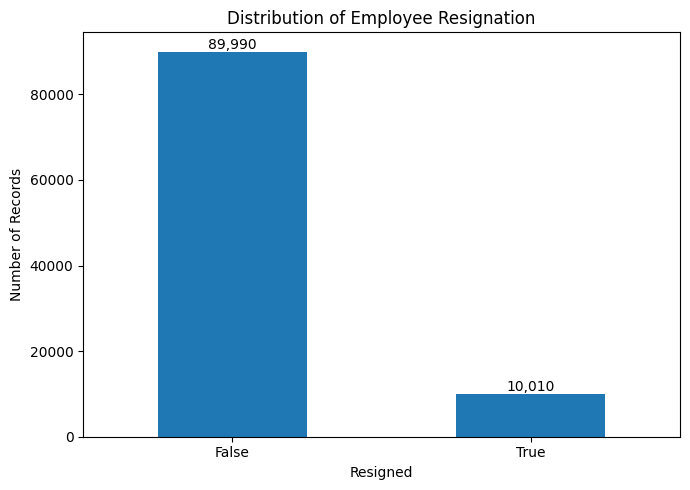

Target distribution chart saved successfully.


In [40]:
import matplotlib.pyplot as plt

# Create the folder where presentation images will be stored.
presentation_assets = Path(
    r"C:\Users\chamidu\Desktop\Employee_Resignation_Prediction\presentations\assets"
)

presentation_assets.mkdir(parents=True, exist_ok=True)


# Count the False and True values in the Resigned column.
resigned_counts = df["Resigned"].value_counts().sort_index()


# Create the bar chart.
ax = resigned_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

ax.set_title("Distribution of Employee Resignation")
ax.set_xlabel("Resigned")
ax.set_ylabel("Number of Records")
ax.set_xticklabels(["False", "True"], rotation=0)


# Display the count above each bar.
for container in ax.containers:
    ax.bar_label(container, labels=[f"{value:,}" for value in resigned_counts])


plt.tight_layout()

# Save the chart as an image.
plt.savefig(
    presentation_assets / "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Target distribution chart saved successfully.")

### Target Distribution Interpretation

- 89,990 records (89.99%) have `Resigned = False`.
- 10,010 records (10.01%) have `Resigned = True`.
- The target variable is therefore highly imbalanced.
- Accuracy alone may be misleading because predicting `False` for every record would already produce 89.99% accuracy.
- Imbalance-aware evaluation metrics will be required during model evaluation.

In [42]:
# Create a descriptive-statistics table for the genuine numerical columns.
numerical_summary = (
    df[numerical_columns]
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "Column"})
)

# Display the summary.
display(numerical_summary)

# Save it in the results folder.
numerical_summary.to_csv(
    results_folder / "numerical_summary.csv",
    index=False
)

print("Numerical summary saved successfully.")

,Column,count,mean,std,min,25%,50%,75%,max
0,Age,100000.0,41.029410,11.244121,22.0,31.00,41.0,51.00,60.0
1,Years_At_Company,100000.0,4.476070,2.869336,0.0,2.00,4.0,7.00,10.0
2,Performance_Score,100000.0,2.995430,1.414726,1.0,2.00,3.0,4.00,5.0
3,Monthly_Salary,100000.0,6403.211000,1372.508717,3850.0,5250.00,6500.0,7500.00,9000.0
4,Work_Hours_Per_Week,100000.0,44.956950,8.942003,30.0,37.00,45.0,53.00,60.0
5,Projects_Handled,100000.0,24.431170,14.469584,0.0,12.00,24.0,37.00,49.0
6,Overtime_Hours,100000.0,14.514930,8.664026,0.0,7.00,15.0,22.00,29.0
7,Sick_Days,100000.0,7.008550,4.331591,0.0,3.00,7.0,11.00,14.0
8,Remote_Work_Frequency,100000.0,50.090500,35.351157,0.0,25.00,50.0,75.00,100.0
9,Team_Size,100000.0,10.013560,5.495405,1.0,5.00,10.0,15.00,19.0


Numerical summary saved successfully.


In [43]:
# Create one table containing the category counts
# for Department, Gender, Job_Title, and Education_Level.

categorical_summary_parts = []

for column in categorical_columns:
    column_summary = (
        df[column]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    column_summary.insert(0, "Column", column)

    column_summary["Percentage"] = (
        column_summary["Count"] / len(df) * 100
    )

    categorical_summary_parts.append(column_summary)


# Combine all categorical summaries into one table.
categorical_summary = pd.concat(
    categorical_summary_parts,
    ignore_index=True
)

# Display the complete table.
display(categorical_summary)


# Save it inside the results folder.
categorical_summary.to_csv(
    results_folder / "categorical_summary.csv",
    index=False
)

print("Categorical summary saved successfully.")

,Column,Category,Count,Percentage
0,Department,Marketing,11216,11.216
1,Department,Finance,11200,11.200
2,Department,Operations,11181,11.181
3,Department,IT,11131,11.131
4,Department,Sales,11122,11.122
5,Department,Legal,11118,11.118
6,Department,Customer Support,11116,11.116
7,Department,HR,10960,10.960
8,Department,Engineering,10956,10.956
9,Gender,Male,48031,48.031


Categorical summary saved successfully.


In [44]:
# Display every file currently saved inside the results folder.
for file in sorted(results_folder.iterdir()):
    print(file.name)

categorical_summary.csv
dataset_audit_summary.csv
dataset_structure_summary.csv
numerical_summary.csv
target_distribution.csv
